In [52]:
import pandas as pd
import numpy as np
import random as rd
from sklearn.decomposition import PCA
from sklearn.preprocessing  import StandardScaler
import matplotlib.pyplot as plt

In [53]:
genes = ['gene' + str(i) for i in range(1, 101)]

wt= ['wt' + str(i) for i in range(1, 6)] #wild type samples
ko = ['ko' + str(i) for i in range(1, 6)] # knock out samples

In [54]:
data = pd.DataFrame(columns=[*wt, *ko], index=genes)
""" * is used to indicate each wt is a cloumn if * not used instead of 12 columns it will create only 2 columns of 
[['wt1', 'wt2', 'wt3', 'wt4', 'wt5']
['ko1', 'ko2', 'ko3', 'ko4', 'ko5']]

"""

" * is used to indicate each wt is a cloumn if * not used instead of 12 columns it will create only 2 columns of \n[['wt1', 'wt2', 'wt3', 'wt4', 'wt5']\n['ko1', 'ko2', 'ko3', 'ko4', 'ko5']]\n\n"

In [55]:
# random data
for gene in data.index:
    data.loc[gene, 'wt1':'wt5'] = np.random.poisson(lam=rd.randrange(10, 1000), size=5)
    data.loc[gene, 'ko1':'ko5'] = np.random.poisson(lam=rd.randrange(10, 1000), size=5)

In [56]:
data.head()

,wt1,wt2,wt3,wt4,wt5,ko1,ko2,ko3,ko4,ko5
gene1,906,944,945,929,939,779,748,818,836,824
gene2,132,155,160,158,155,804,825,807,835,839
gene3,981,957,1009,957,990,333,327,311,372,310
gene4,868,927,867,898,933,329,297,288,295,289
gene5,856,881,837,871,908,918,908,870,944,883


In [57]:
data.tail()

,wt1,wt2,wt3,wt4,wt5,ko1,ko2,ko3,ko4,ko5
gene96,860,820,803,813,880,981,979,1004,1009,1039
gene97,803,768,692,790,796,148,153,132,152,147
gene98,567,525,537,557,494,29,20,24,22,26
gene99,681,699,694,704,693,972,981,990,925,970
gene100,907,894,894,994,898,626,688,675,665,709


In [58]:
data.shape

(100, 10)

In [59]:
data.info()

<class 'pandas.DataFrame'>
Index: 100 entries, gene1 to gene100
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   wt1     100 non-null    object
 1   wt2     100 non-null    object
 2   wt3     100 non-null    object
 3   wt4     100 non-null    object
 4   wt5     100 non-null    object
 5   ko1     100 non-null    object
 6   ko2     100 non-null    object
 7   ko3     100 non-null    object
 8   ko4     100 non-null    object
 9   ko5     100 non-null    object
dtypes: object(10)
memory usage: 12.7+ KB


In [60]:
data.describe()

,wt1,wt2,wt3,wt4,wt5,ko1,ko2,ko3,ko4,ko5
count,100,100,100,100,100,100,100,100,100,100
unique,97,92,92,93,94,97,96,98,97,93
top,345,111,945,26,350,159,75,642,335,358
freq,2,3,2,3,2,2,2,2,2,2


##### Scale and center data


In [65]:
scaled_data = StandardScaler().fit_transform(data.T) # here samples are columns and features are rows 


In [62]:
pca = PCA()
pca.fit(scaled_data)
pca_data= pca.transform(scaled_data)
percent_var = np.round(pca.explained_variance_ratio_*100, decimals=1)
print(percent_var)
labels =['PC' +str(x) for x in range(1, len(percent_var)+1)]

[88.2  3.1  2.1  2.   1.5  1.2  0.8  0.6  0.4  0. ]


Text(0.5, 1.0, 'Scree plot')

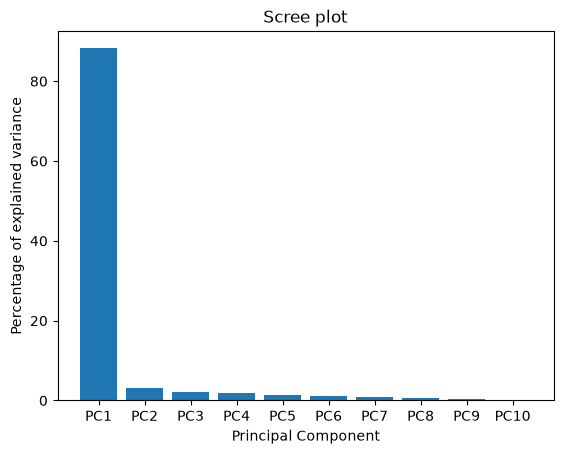

In [63]:
plt.bar(x=range(1, len(percent_var)+1), height=percent_var, tick_label=labels)
plt.ylabel('Percentage of explained variance')
plt.xlabel('Principal Component')
plt.title('Scree plot')

In [ ]:
pca_df = pd.DataFrame(pca_data, index=[*wt, *ko], columns=labels)


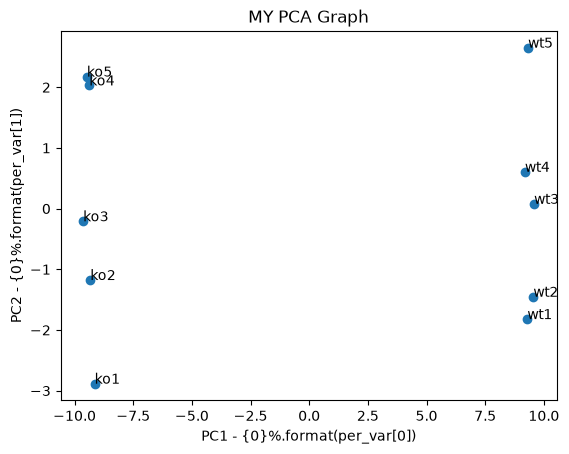

In [67]:
plt.scatter(pca_df.PC1, pca_df.PC2)
plt.title('MY PCA Graph')
plt.xlabel('PC1 - {0}%.format(per_var[0])')
plt.ylabel('PC2 - {0}%.format(per_var[1])')
for sample in pca_df.index:
    plt.annotate(sample, (pca_df.PC1.loc[sample], pca_df.PC2.loc[sample]))

In [71]:
loading_scores = pd.Series(pca.components_[0], index=genes)
sorted_loading_scores = loading_scores.abs().sort_values(ascending=False)
top_10_genes = sorted_loading_scores[0:10].index.values

In [72]:
print(loading_scores[top_10_genes])

gene33    0.106454
gene4     0.106426
gene92   -0.106424
gene57    0.106422
gene44    0.106421
gene55    0.106418
gene91   -0.106417
gene28   -0.106400
gene21   -0.106391
gene82    0.106375
dtype: float64
